<a href="https://colab.research.google.com/github/jungmee0807-droid/26-2-DIP-JeongmiMa-202301846-/blob/main/HW/HW05.ipynb" target="_parent"><img src="https://colab.research.google.com/assets/colab-badge.svg" alt="Open In Colab"/></a>

In [1]:
import numpy as np
import matplotlib.pyplot as plt
import scipy.signal as signal
import scipy.ndimage as nd
from PIL import Image

In [6]:
from google.colab import drive
drive.mount('/content/drive')
imgpath = '/content/drive/MyDrive/DIP4E'

Drive already mounted at /content/drive; to attempt to forcibly remount, call drive.mount("/content/drive", force_remount=True).


## 1. object counting에 사용할 image를 grayscale로 불러오기

(3024, 4032) uint8


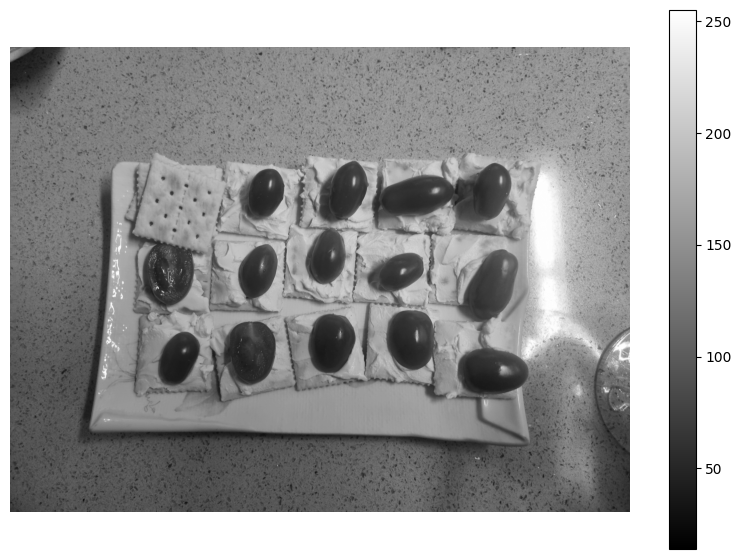

In [10]:
I = Image.open(os.path.join(imgpath, '20250506_185546.jpg')).convert('L')
f = np.array(I)
print(f.shape, f.dtype)

plt.figure(figsize=(10, 7))
plt.imshow(f, cmap='gray')
plt.axis('off')
plt.colorbar()
plt.show()

## 2. 적절한 전처리를 통해 영상의 noise를 줄이기

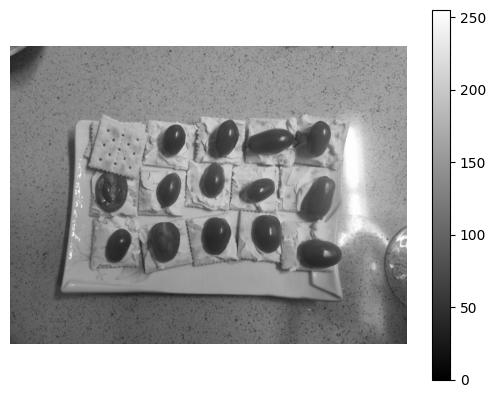

In [11]:
f_denoised = signal.medfilt2d(f,7)
plt.imshow(f_denoised,cmap='gray')
plt.axis('off')
plt.colorbar()
plt.show()

ROI+median filter

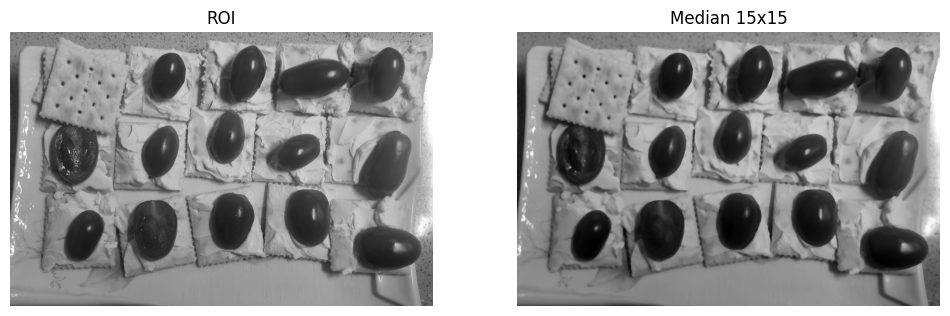

In [12]:
import cv2
from scipy import ndimage

# 접시 영역만 자르기 (행, 열 범위) - 결과 보고 숫자 조금씩 조정
roi = f[650:2500, 600:3450]

f_denoised = cv2.medianBlur(roi, 15)   # signal.medfilt2d보다 훨씬 빠름

plt.figure(figsize=(12,5))
plt.subplot(1,2,1); plt.imshow(roi, cmap='gray'); plt.title('ROI'); plt.axis('off')
plt.subplot(1,2,2); plt.imshow(f_denoised, cmap='gray'); plt.title('Median 15x15'); plt.axis('off')
plt.show()

## 3. 적절한 임계값을 찾아 thresholding을 통해 binary mask를 생성하기

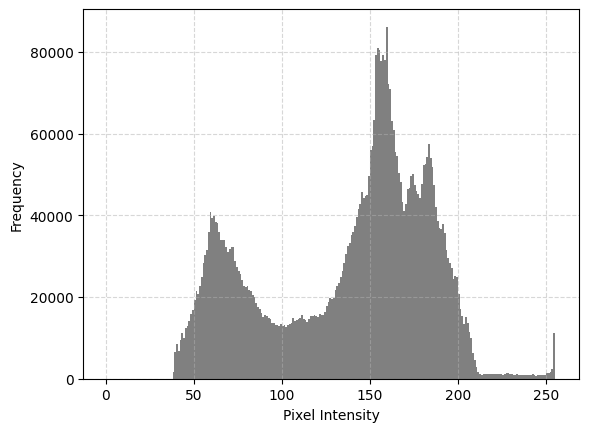

In [13]:
plt.hist(f_denoised.ravel(), bins=256, range=(0,256), color='gray')
plt.xlabel('Pixel Intensity')
plt.ylabel('Frequency')
plt.grid(True, linestyle='--', alpha=0.5)
plt.show()

Otsu threshold: 120.0


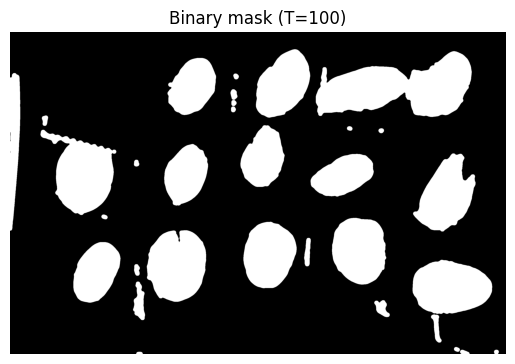

In [15]:
T, _ = cv2.threshold(f_denoised, 0, 255, cv2.THRESH_BINARY + cv2.THRESH_OTSU)
print('Otsu threshold:', T)

T = 100                      # 히스토그램 보고 조정
mask = f_denoised < T        # 토마토가 어두우니까 T보다 작은 쪽

k = cv2.getStructuringElement(cv2.MORPH_ELLIPSE, (25, 25))
mask = cv2.morphologyEx(mask.astype(np.uint8), cv2.MORPH_OPEN, k)
mask = ndimage.binary_fill_holes(mask)

plt.imshow(mask, cmap='gray'); plt.title(f'Binary mask (T={T})'); plt.axis('off'); plt.show()

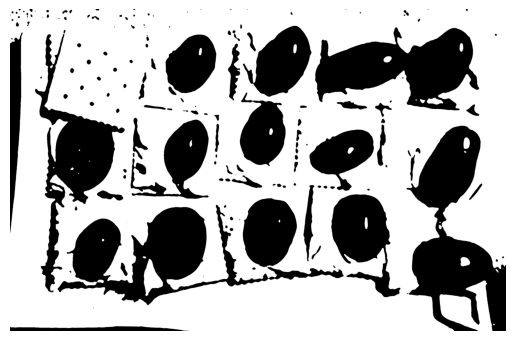

In [14]:
th_val = 128
f_mask = f_denoised > th_val
plt.imshow(f_mask,cmap='gray')
plt.axis('off')
plt.show()

Otsu threshold: 120.0


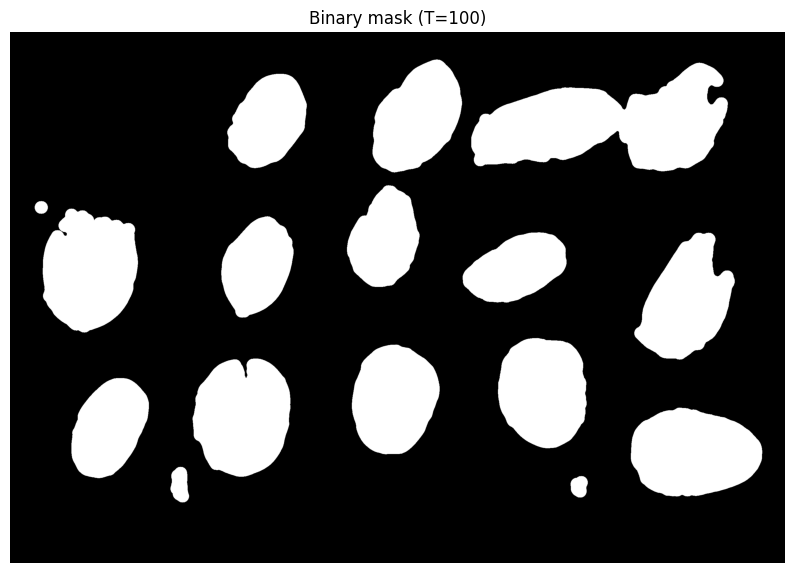

In [17]:
T, _ = cv2.threshold(f_denoised, 0, 255, cv2.THRESH_BINARY + cv2.THRESH_OTSU)
print('Otsu threshold:', T)

T = 100                      # 히스토그램 골짜기 값
mask = f_denoised < T        # 토마토가 어두우니까 T보다 작은 쪽

k = cv2.getStructuringElement(cv2.MORPH_ELLIPSE, (45, 45))
mask = cv2.morphologyEx(mask.astype(np.uint8), cv2.MORPH_OPEN, k)
mask = ndimage.binary_fill_holes(mask)

plt.figure(figsize=(10,7))
plt.imshow(mask, cmap='gray'); plt.title(f'Binary mask (T={T})'); plt.axis('off'); plt.show()

## 4. Connected component 추출을 통해 object를 분리하고, 각각의 pixel수를 계산하기

전체 component 수: 16


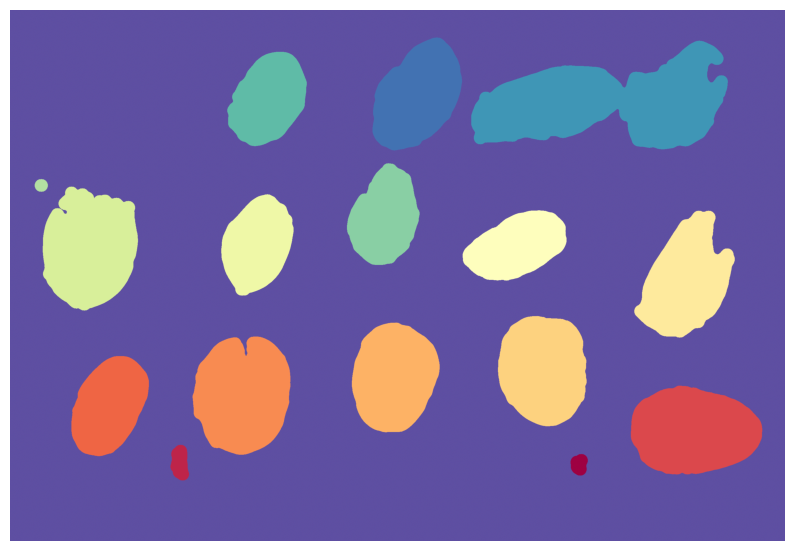

In [18]:
labels, nums = ndimage.label(mask)
print('전체 component 수:', nums)

plt.figure(figsize=(10,7))
plt.imshow(labels, cmap='Spectral_r')
plt.axis('off')
plt.show()

In [20]:
cc = np.zeros((nums, 2))
for i in range(1, nums+1):
    cc[i-1, 0] = i
    cc[i-1, 1] = np.sum(labels == i)
    print(f'index: {i}, number of pixels: {int(cc[i-1,1])}')

# 작은 잔여물(크래커 그림자, 점) 제거
min_area = 20000
cc = cc[cc[:,1] >= min_area]
print(f'\n면적 {min_area} 이상 object 수: {len(cc)}')
for idx, area in cc:
    print(f'index: {int(idx)}, number of pixels: {int(area)}')

index: 1, number of pixels: 85455
index: 2, number of pixels: 201536
index: 3, number of pixels: 64932
index: 4, number of pixels: 62615
index: 5, number of pixels: 1606
index: 6, number of pixels: 110255
index: 7, number of pixels: 62961
index: 8, number of pixels: 60859
index: 9, number of pixels: 94589
index: 10, number of pixels: 95565
index: 11, number of pixels: 89391
index: 12, number of pixels: 110514
index: 13, number of pixels: 67672
index: 14, number of pixels: 109462
index: 15, number of pixels: 6224
index: 16, number of pixels: 3556

면적 20000 이상 object 수: 13
index: 1, number of pixels: 85455
index: 2, number of pixels: 201536
index: 3, number of pixels: 64932
index: 4, number of pixels: 62615
index: 6, number of pixels: 110255
index: 7, number of pixels: 62961
index: 8, number of pixels: 60859
index: 9, number of pixels: 94589
index: 10, number of pixels: 95565
index: 11, number of pixels: 89391
index: 12, number of pixels: 110514
index: 13, number of pixels: 67672
index: 

씨앗 수: 14
전체 component 수: 14


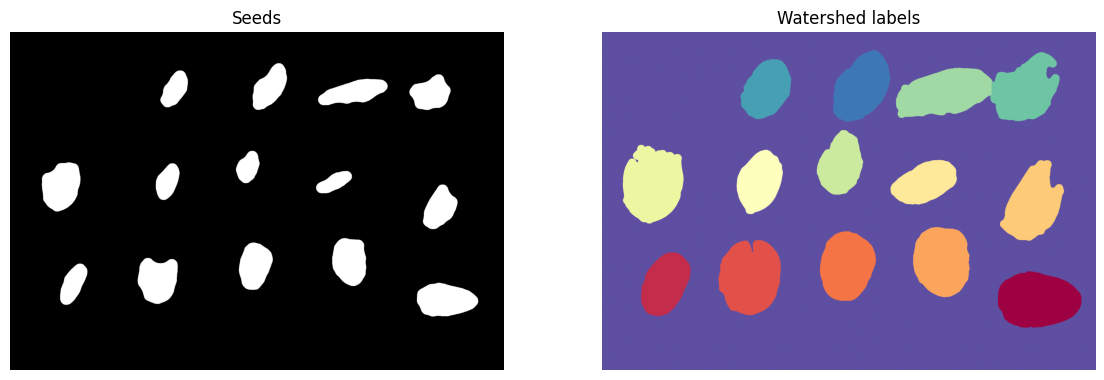

In [22]:
from skimage.segmentation import watershed

# 1) 크게 erosion → 붙은 토마토 사이가 끊어지고 토마토마다 씨앗이 남음
k_er = cv2.getStructuringElement(cv2.MORPH_ELLIPSE, (181, 181))
seeds = cv2.erode(mask.astype(np.uint8), k_er)

# 2) 씨앗을 살짝 dilation → 한 토마토 안에서 쪼개진 씨앗 조각을 다시 합침
k_di = cv2.getStructuringElement(cv2.MORPH_ELLIPSE, (61, 61))
seeds = cv2.dilate(seeds, k_di) & mask.astype(np.uint8)

markers, n_seeds = ndimage.label(seeds)
print('씨앗 수:', n_seeds)

# 3) 씨앗을 원래 mask 모양까지 다시 키우기 (watershed)
dist = ndimage.distance_transform_edt(mask)
labels = watershed(-dist, markers, mask=mask)
nums = labels.max()
print('전체 component 수:', nums)

plt.figure(figsize=(14,6))
plt.subplot(1,2,1); plt.imshow(seeds, cmap='gray'); plt.title('Seeds'); plt.axis('off')
plt.subplot(1,2,2); plt.imshow(labels, cmap='Spectral_r'); plt.title('Watershed labels'); plt.axis('off')
plt.show()

In [23]:
cc = np.zeros((nums, 2))
for i in range(1, nums+1):
    cc[i-1, 0] = i
    cc[i-1, 1] = np.sum(labels == i)
    print(f'index: {i}, number of pixels: {int(cc[i-1,1])}')

# 작은 잔여물 제거
min_area = 20000
cc = cc[cc[:,1] >= min_area]
print(f'\n면적 {min_area} 이상 object 수: {len(cc)}')
for idx, area in cc:
    print(f'index: {int(idx)}, number of pixels: {int(area)}')

index: 1, number of pixels: 85455
index: 2, number of pixels: 64932
index: 3, number of pixels: 96696
index: 4, number of pixels: 104840
index: 5, number of pixels: 62615
index: 6, number of pixels: 110255
index: 7, number of pixels: 62961
index: 8, number of pixels: 60859
index: 9, number of pixels: 94589
index: 10, number of pixels: 95565
index: 11, number of pixels: 89391
index: 12, number of pixels: 110514
index: 13, number of pixels: 67672
index: 14, number of pixels: 109462

면적 20000 이상 object 수: 14
index: 1, number of pixels: 85455
index: 2, number of pixels: 64932
index: 3, number of pixels: 96696
index: 4, number of pixels: 104840
index: 5, number of pixels: 62615
index: 6, number of pixels: 110255
index: 7, number of pixels: 62961
index: 8, number of pixels: 60859
index: 9, number of pixels: 94589
index: 10, number of pixels: 95565
index: 11, number of pixels: 89391
index: 12, number of pixels: 110514
index: 13, number of pixels: 67672
index: 14, number of pixels: 109462


가장 큰 object: index 12, 110514 pixels
가장 작은 object: index 8, 60859 pixels


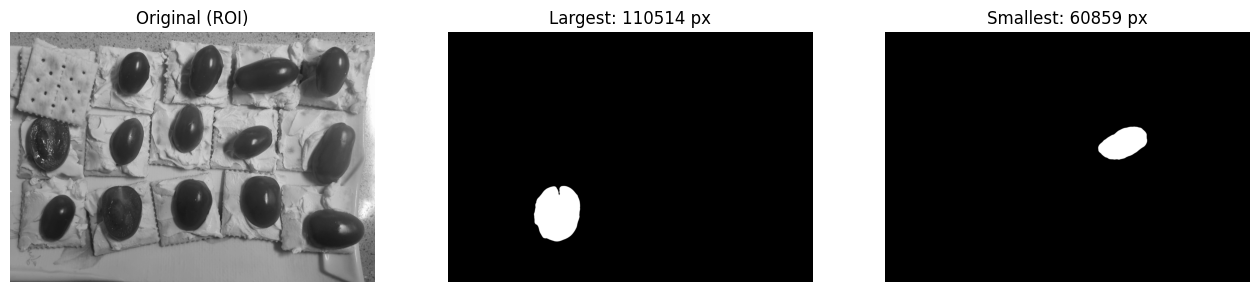

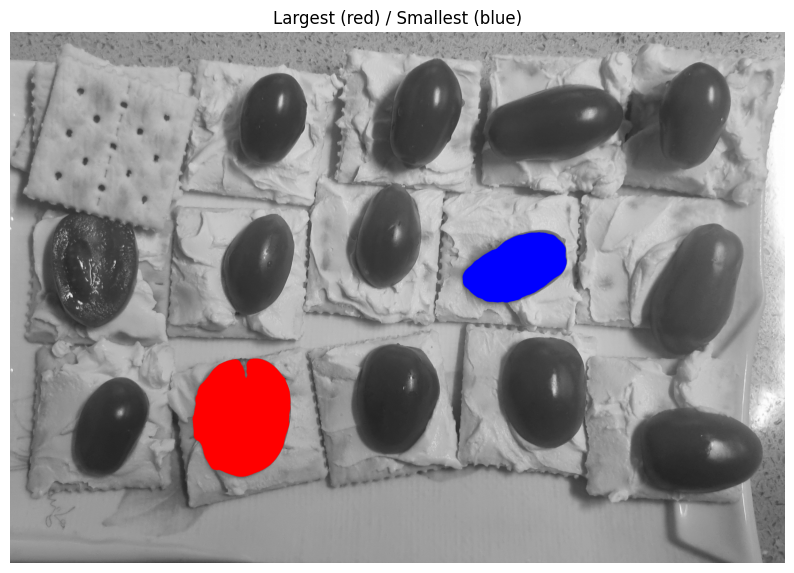

In [24]:
big   = int(cc[np.argmax(cc[:,1]), 0])
small = int(cc[np.argmin(cc[:,1]), 0])
print(f'가장 큰 object: index {big}, {int(cc[:,1].max())} pixels')
print(f'가장 작은 object: index {small}, {int(cc[:,1].min())} pixels')

plt.figure(figsize=(16,5))
plt.subplot(1,3,1); plt.imshow(roi, cmap='gray'); plt.title('Original (ROI)'); plt.axis('off')
plt.subplot(1,3,2); plt.imshow(labels==big, cmap='gray');   plt.title(f'Largest: {int(cc[:,1].max())} px');  plt.axis('off')
plt.subplot(1,3,3); plt.imshow(labels==small, cmap='gray'); plt.title(f'Smallest: {int(cc[:,1].min())} px'); plt.axis('off')
plt.show()

# 원본 위에 겹쳐서 표시 (빨강=가장 큼, 파랑=가장 작음)
overlay = np.stack([roi]*3, axis=-1).copy()
overlay[labels==big]   = [255, 0, 0]
overlay[labels==small] = [0, 0, 255]
plt.figure(figsize=(10,7))
plt.imshow(overlay); plt.title('Largest (red) / Smallest (blue)'); plt.axis('off')
plt.show()

인접한 토마토 두 개가 하나로 잡혀서 erosion으로 씨앗을 만들고 watershed로 분리 → 14개, 면적 20,000px 미만 제거
가장 큰 것(자른 토마토, 110,514px)과 가장 작은 것(60,859px) 시각화


## 5. 추출한 connected component 중 가장 큰 것과 작은 것을 시각화하기

In [25]:
ind_max = np.argmax(cc[:,1])
print(f'the largest component: index {int(cc[ind_max,0])}, # of pixels: {int(cc[ind_max,1])}')
ind_min = np.argmin(cc[:,1])
print(f'the smallest component: index {int(cc[ind_min,0])}, # of pixels: {int(cc[ind_min,1])}')

the largest component: index 12, # of pixels: 110514
the smallest component: index 8, # of pixels: 60859


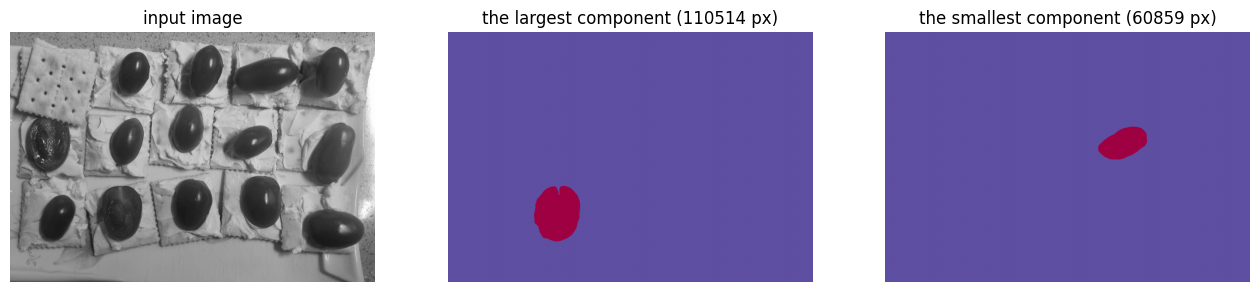

In [26]:
plt.figure(figsize=(16,9))
plt.subplot(131)
plt.imshow(roi, cmap='gray')
plt.axis('off')
plt.title('input image')
plt.subplot(132)
plt.imshow(labels==cc[ind_max,0], cmap='Spectral_r')
plt.axis('off')
plt.title(f'the largest component ({int(cc[ind_max,1])} px)')
plt.subplot(133)
plt.imshow(labels==cc[ind_min,0], cmap='Spectral_r')
plt.axis('off')
plt.title(f'the smallest component ({int(cc[ind_min,1])} px)')
plt.show()

<dots 사진>

(310, 446) uint8


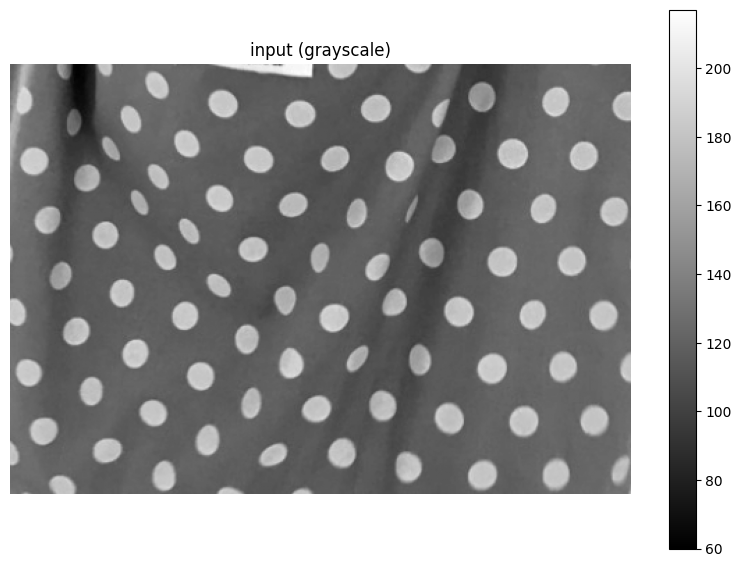

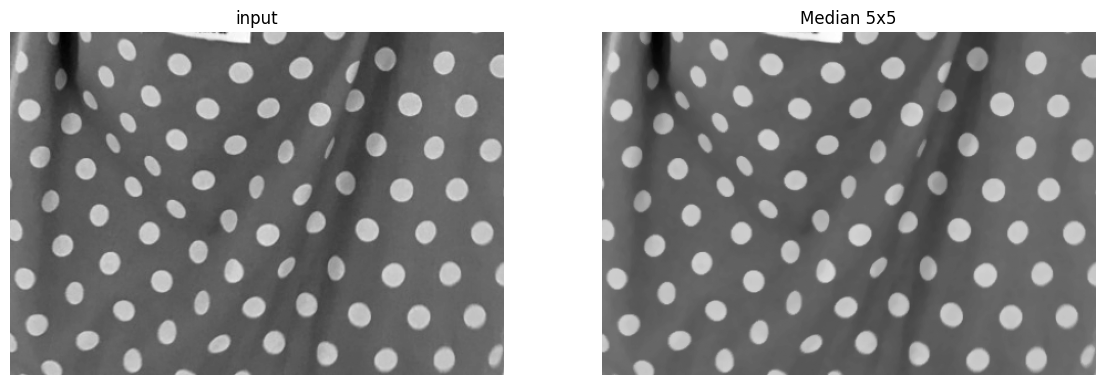

Otsu threshold: 145.0


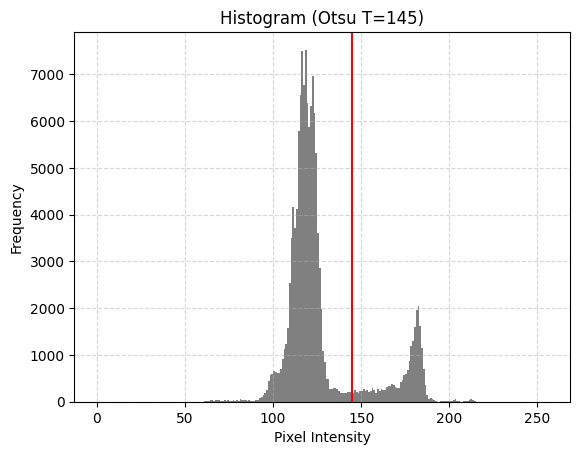

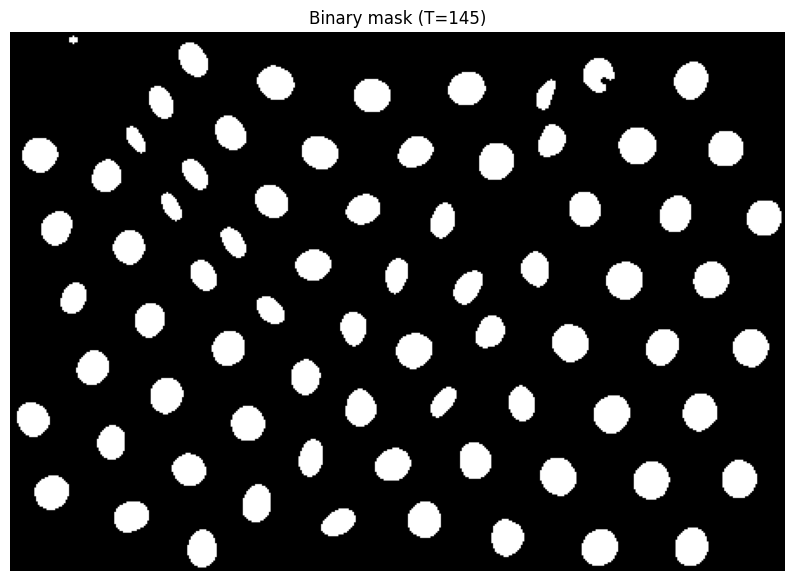

object 수: 73
index: 2, number of pixels: 256
index: 3, number of pixels: 250
index: 4, number of pixels: 329
index: 5, number of pixels: 325
index: 6, number of pixels: 329
index: 7, number of pixels: 329
index: 8, number of pixels: 130
index: 9, number of pixels: 206
index: 10, number of pixels: 277
index: 11, number of pixels: 228
index: 12, number of pixels: 113
index: 13, number of pixels: 365
index: 14, number of pixels: 335
index: 15, number of pixels: 320
index: 16, number of pixels: 281
index: 17, number of pixels: 320
index: 18, number of pixels: 349
index: 19, number of pixels: 250
index: 20, number of pixels: 189
index: 21, number of pixels: 288
index: 22, number of pixels: 128
index: 23, number of pixels: 295
index: 24, number of pixels: 267
index: 25, number of pixels: 308
index: 26, number of pixels: 331
index: 27, number of pixels: 222
index: 28, number of pixels: 275
index: 29, number of pixels: 177
index: 30, number of pixels: 283
index: 31, number of pixels: 290
index

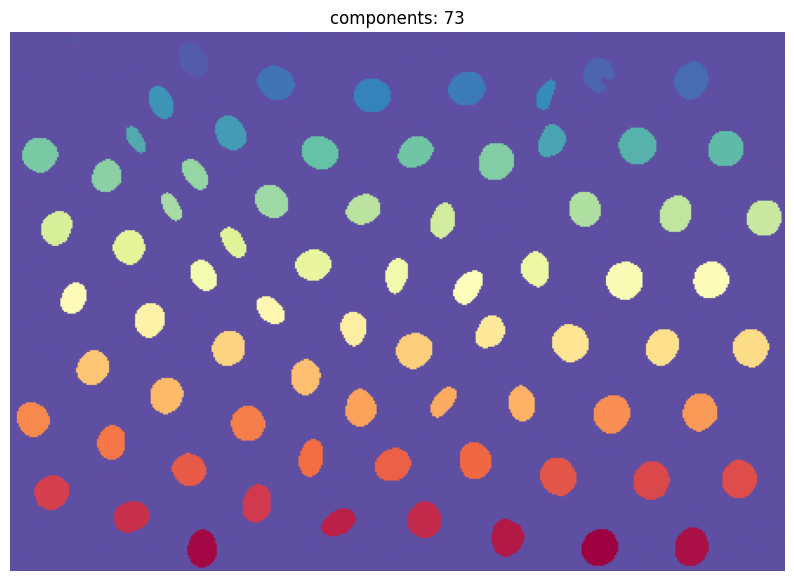

the largest component: index 13, # of pixels: 365
the smallest component: index 12, # of pixels: 113


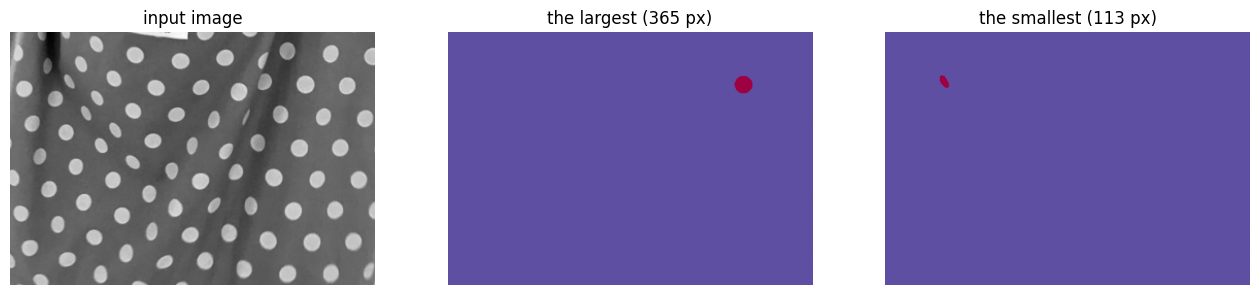

In [29]:
import os, cv2
import numpy as np
import matplotlib.pyplot as plt
from PIL import Image
from scipy import ndimage
from skimage.segmentation import clear_border

imgpath = '/content/drive/MyDrive/DIP4E'

# ===== 1. object counting에 사용할 image를 grayscale로 불러오기 =====
I2 = Image.open(os.path.join(imgpath, 'dots.png')).convert('L')
f2 = np.array(I2)
print(f2.shape, f2.dtype)
plt.figure(figsize=(10,7)); plt.imshow(f2, cmap='gray'); plt.axis('off'); plt.colorbar(); plt.title('input (grayscale)'); plt.show()

# ===== 2. 적절한 전처리를 통해 영상의 noise를 줄이기 =====
f2_denoised = cv2.medianBlur(f2, 5)    # 5x5 median filter

plt.figure(figsize=(14,5))
plt.subplot(121); plt.imshow(f2, cmap='gray'); plt.title('input'); plt.axis('off')
plt.subplot(122); plt.imshow(f2_denoised, cmap='gray'); plt.title('Median 5x5'); plt.axis('off')
plt.show()

# ===== 3. 적절한 임계값을 찾아 thresholding을 통해 binary mask를 생성하기 =====
T2, _ = cv2.threshold(f2_denoised, 0, 255, cv2.THRESH_BINARY + cv2.THRESH_OTSU)
print('Otsu threshold:', T2)

plt.hist(f2_denoised.ravel(), bins=256, range=(0,256), color='gray'); plt.axvline(T2, color='r')
plt.xlabel('Pixel Intensity'); plt.ylabel('Frequency'); plt.grid(True, linestyle='--', alpha=0.5)
plt.title(f'Histogram (Otsu T={T2:.0f})'); plt.show()

mask2 = (f2_denoised > T2).astype(np.uint8)     # 노란 점이 밝으므로 T보다 큰 쪽
mask2 = cv2.morphologyEx(mask2, cv2.MORPH_OPEN, cv2.getStructuringElement(cv2.MORPH_ELLIPSE, (5,5)))
mask2 = ndimage.binary_fill_holes(mask2)
mask2 = clear_border(mask2)                     # 테두리에 걸린 옷 라벨, 잘린 점 제거

plt.figure(figsize=(10,7)); plt.imshow(mask2, cmap='gray'); plt.title(f'Binary mask (T={T2:.0f})'); plt.axis('off'); plt.show()

# ===== 4. Connected component 추출을 통해 object를 분리하고, 각각의 pixel수를 계산하기 =====
labels2, nums2 = ndimage.label(mask2)
cc2 = np.zeros((nums2, 2))
for i in range(1, nums2+1):
    cc2[i-1, 0] = i
    cc2[i-1, 1] = np.sum(labels2 == i)

min_area2 = 100                                 # 아주 작은 잔여 조각 제거
cc2 = cc2[cc2[:,1] >= min_area2]
print('object 수:', len(cc2))
for idx, area in cc2:
    print(f'index: {int(idx)}, number of pixels: {int(area)}')

plt.figure(figsize=(10,7)); plt.imshow(labels2, cmap='Spectral_r'); plt.title(f'components: {len(cc2)}'); plt.axis('off'); plt.show()

# ===== 5. 추출한 connected component 중 가장 큰 것과 작은 것을 시각화하기 =====
ind_max2 = np.argmax(cc2[:,1]); ind_min2 = np.argmin(cc2[:,1])
print(f'the largest component: index {int(cc2[ind_max2,0])}, # of pixels: {int(cc2[ind_max2,1])}')
print(f'the smallest component: index {int(cc2[ind_min2,0])}, # of pixels: {int(cc2[ind_min2,1])}')

plt.figure(figsize=(16,9))
plt.subplot(131); plt.imshow(f2, cmap='gray'); plt.axis('off'); plt.title('input image')
plt.subplot(132); plt.imshow(labels2==cc2[ind_max2,0], cmap='Spectral_r'); plt.axis('off'); plt.title(f'the largest ({int(cc2[ind_max2,1])} px)')
plt.subplot(133); plt.imshow(labels2==cc2[ind_min2,0], cmap='Spectral_r'); plt.axis('off'); plt.title(f'the smallest ({int(cc2[ind_min2,1])} px)')
plt.show()

<토마토>

(3024, 4032) uint8


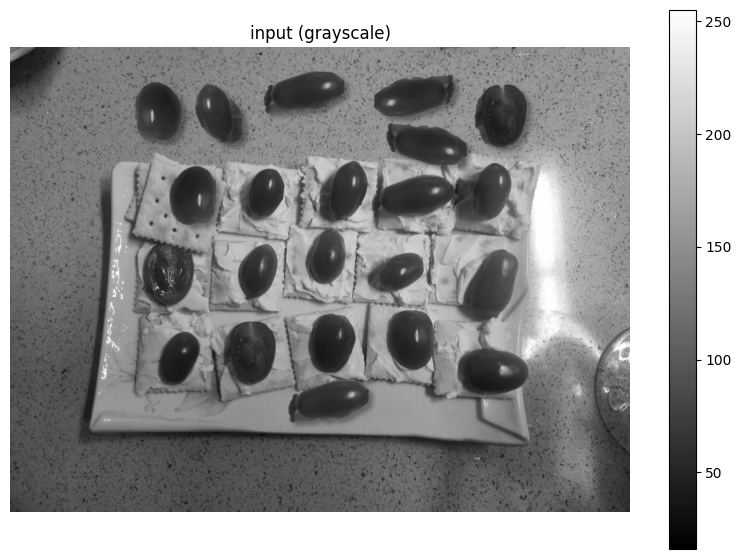

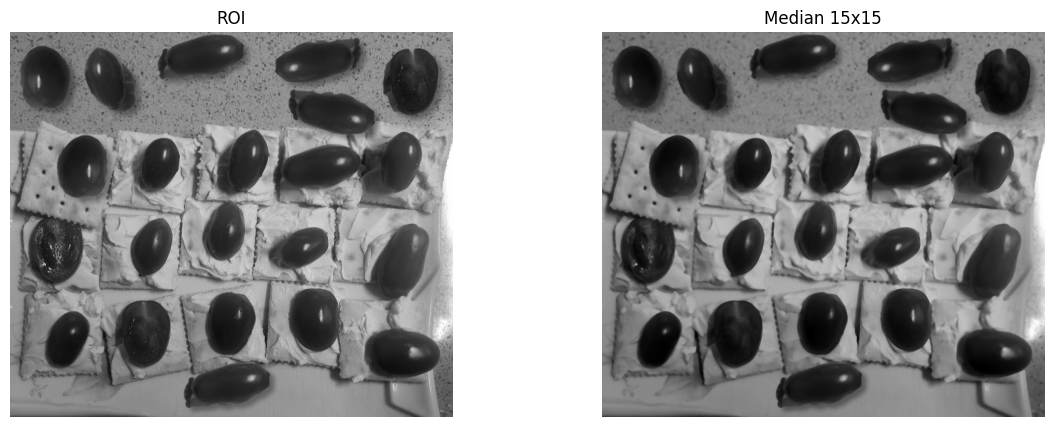

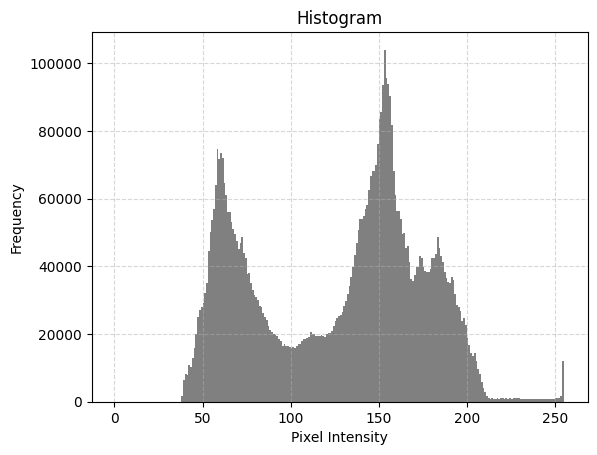

Otsu threshold: 116.0


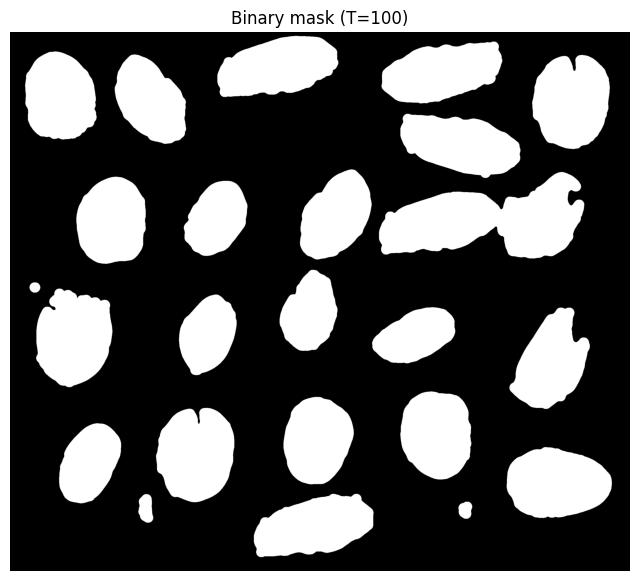

씨앗 수: 22 / component 수: 22


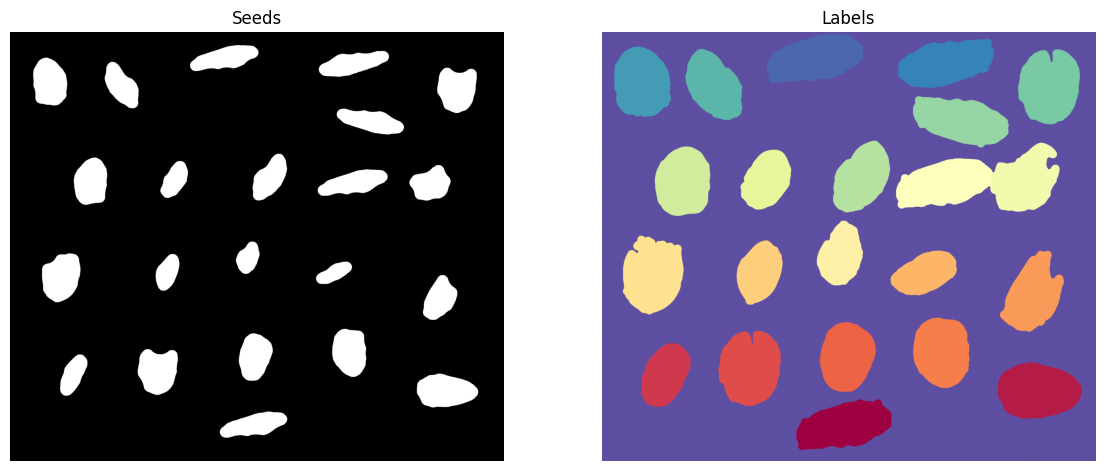

object 수: 22
index: 1, number of pixels: 103458
index: 2, number of pixels: 103022
index: 3, number of pixels: 96097
index: 4, number of pixels: 84277
index: 5, number of pixels: 108813
index: 6, number of pixels: 102365
index: 7, number of pixels: 85382
index: 8, number of pixels: 92885
index: 9, number of pixels: 64836
index: 10, number of pixels: 96939
index: 11, number of pixels: 104993
index: 12, number of pixels: 62651
index: 13, number of pixels: 109897
index: 14, number of pixels: 62849
index: 15, number of pixels: 60849
index: 16, number of pixels: 94771
index: 17, number of pixels: 95569
index: 18, number of pixels: 89455
index: 19, number of pixels: 110388
index: 20, number of pixels: 67680
index: 21, number of pixels: 109414
index: 22, number of pixels: 103464
the largest component: index 19, # of pixels: 110388
the smallest component: index 15, # of pixels: 60849


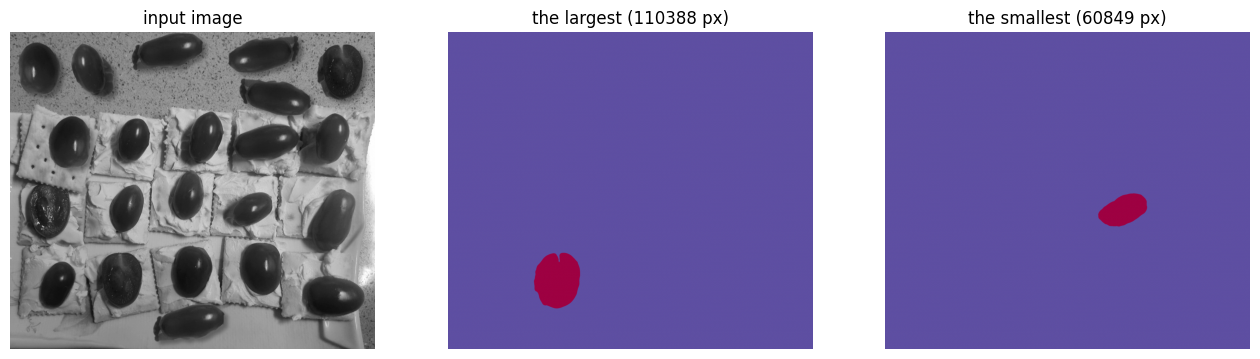

In [30]:
import os, cv2
import numpy as np
import matplotlib.pyplot as plt
from PIL import Image
from scipy import ndimage
from skimage.segmentation import watershed

imgpath = '/content/drive/MyDrive/DIP4E'

# ===== 1. object counting에 사용할 image를 grayscale로 불러오기 =====
I = Image.open(os.path.join(imgpath, 'tomato_final.jpg')).convert('L')
f = np.array(I)
print(f.shape, f.dtype)
plt.figure(figsize=(10,7)); plt.imshow(f, cmap='gray'); plt.axis('off'); plt.colorbar(); plt.title('input (grayscale)'); plt.show()

# ===== 2. 적절한 전처리를 통해 영상의 noise를 줄이기 =====
roi = f[150:2500, 750:3450]            # 접시와 토마토 영역만 사용
f_denoised = cv2.medianBlur(roi, 15)   # 15x15 median filter

plt.figure(figsize=(14,5))
plt.subplot(121); plt.imshow(roi, cmap='gray'); plt.title('ROI'); plt.axis('off')
plt.subplot(122); plt.imshow(f_denoised, cmap='gray'); plt.title('Median 15x15'); plt.axis('off')
plt.show()

# ===== 3. 적절한 임계값을 찾아 thresholding을 통해 binary mask를 생성하기 =====
plt.hist(f_denoised.ravel(), bins=256, range=(0,256), color='gray')
plt.xlabel('Pixel Intensity'); plt.ylabel('Frequency'); plt.grid(True, linestyle='--', alpha=0.5)
plt.title('Histogram'); plt.show()

T_otsu, _ = cv2.threshold(f_denoised, 0, 255, cv2.THRESH_BINARY + cv2.THRESH_OTSU)
print('Otsu threshold:', T_otsu)

T = 100                                     # 토마토 봉우리와 배경 봉우리 사이 골짜기
mask = (f_denoised < T).astype(np.uint8)    # 토마토가 어두우므로 T보다 작은 쪽
k = cv2.getStructuringElement(cv2.MORPH_ELLIPSE, (45, 45))
mask = cv2.morphologyEx(mask, cv2.MORPH_OPEN, k)     # 작은 점 제거
mask = ndimage.binary_fill_holes(mask)               # 반사광 구멍 메우기

plt.figure(figsize=(10,7)); plt.imshow(mask, cmap='gray'); plt.title(f'Binary mask (T={T})'); plt.axis('off'); plt.show()

# ===== 4. Connected component 추출을 통해 object를 분리하고, 각각의 pixel수를 계산하기 =====
# 맞닿은 토마토 분리: erosion으로 씨앗 만들기 → watershed로 원래 모양까지 키우기
seeds = cv2.erode(mask.astype(np.uint8), cv2.getStructuringElement(cv2.MORPH_ELLIPSE, (181, 181)))
seeds = cv2.dilate(seeds, cv2.getStructuringElement(cv2.MORPH_ELLIPSE, (61, 61))) & mask.astype(np.uint8)
markers, n_seeds = ndimage.label(seeds)
labels = watershed(-ndimage.distance_transform_edt(mask), markers, mask=mask)
nums = labels.max()
print('씨앗 수:', n_seeds, '/ component 수:', nums)

plt.figure(figsize=(14,6))
plt.subplot(121); plt.imshow(seeds, cmap='gray'); plt.title('Seeds'); plt.axis('off')
plt.subplot(122); plt.imshow(labels, cmap='Spectral_r'); plt.title('Labels'); plt.axis('off')
plt.show()

cc = np.zeros((nums, 2))
for i in range(1, nums+1):
    cc[i-1, 0] = i
    cc[i-1, 1] = np.sum(labels == i)

min_area = 20000                            # 작은 잔여물 제거
cc = cc[cc[:,1] >= min_area]
print('object 수:', len(cc))
for idx, area in cc:
    print(f'index: {int(idx)}, number of pixels: {int(area)}')

# ===== 5. 추출한 connected component 중 가장 큰 것과 작은 것을 시각화하기 =====
ind_max = np.argmax(cc[:,1]); ind_min = np.argmin(cc[:,1])
print(f'the largest component: index {int(cc[ind_max,0])}, # of pixels: {int(cc[ind_max,1])}')
print(f'the smallest component: index {int(cc[ind_min,0])}, # of pixels: {int(cc[ind_min,1])}')

plt.figure(figsize=(16,9))
plt.subplot(131); plt.imshow(roi, cmap='gray'); plt.axis('off'); plt.title('input image')
plt.subplot(132); plt.imshow(labels==cc[ind_max,0], cmap='Spectral_r'); plt.axis('off'); plt.title(f'the largest ({int(cc[ind_max,1])} px)')
plt.subplot(133); plt.imshow(labels==cc[ind_min,0], cmap='Spectral_r'); plt.axis('off'); plt.title(f'the smallest ({int(cc[ind_min,1])} px)')
plt.show()